# MLT Assignment #4: cats vs dogs, CNN and transfer learning

Mironov Kirill, group J4132

What is done:
- Part 1. A CNN with 3 convolutional layers: training, test accuracy, Loss(epochs) and Accuracy(epochs) curves. The same network once more with data augmentation.
- Part 2. Transfer learning with VGG16 and ResNet-50: test accuracy, learning curves and an inference function for a custom image with the best model.

In all parts the models are trained on `train`, the number of epochs and the best model are chosen on `val`, and `test` is only used for the final numbers.

In [1]:
import os
import sys
import json
import time
import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

warnings.filterwarnings('ignore', category=UserWarning)
torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():          # Apple Silicon GPU
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print('device:', device, '| torch', torch.__version__)

device: mps | torch 2.8.0


## Data

The data is in the unpacked `Cats_and_Dogs` folder. `ImageFolder` takes the classes from the folder names: `cats` is 0, `dogs` is 1.

,train,val,test
cats,10000,1240,1250
dogs,10000,1250,1250


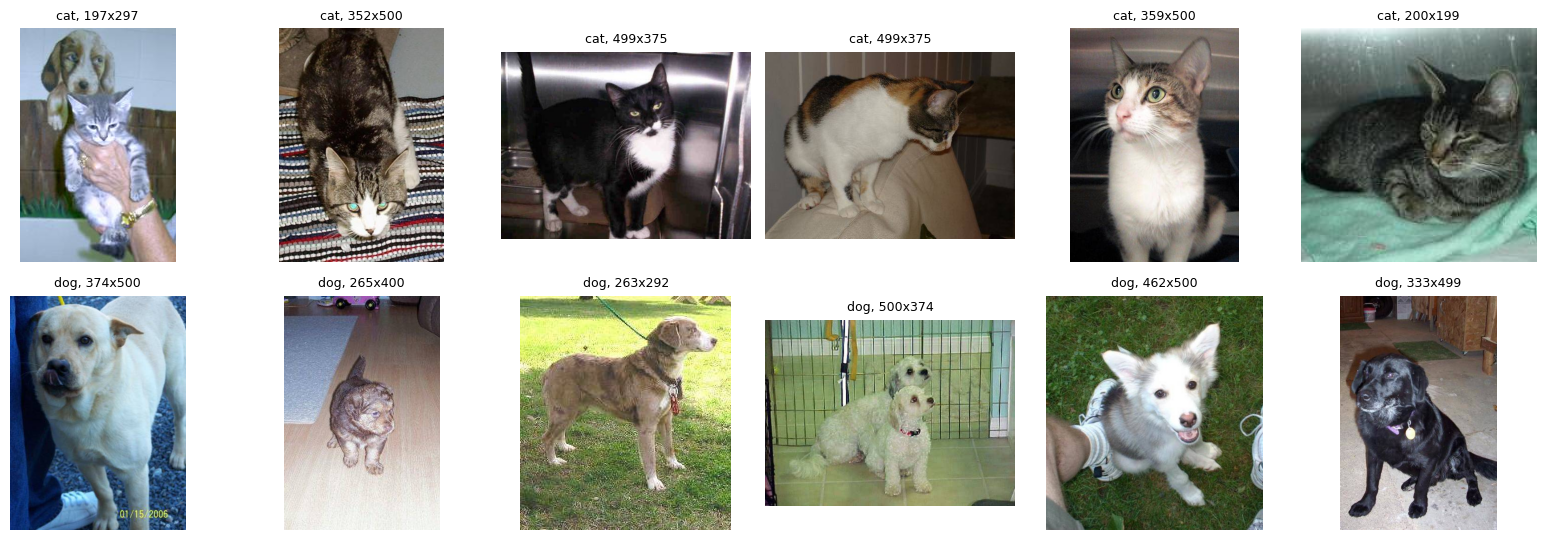

In [2]:
data_dir = 'MLT/Cats_and_Dogs/Cats_and_Dogs'
train = os.path.join(data_dir, 'train')
val = os.path.join(data_dir, 'val')
test = os.path.join(data_dir, 'test')

counts = pd.DataFrame({split: {cls: len(os.listdir(os.path.join(data_dir, split, cls))) for cls in ['cats', 'dogs']}
                       for split in ['train', 'val', 'test']})
display(counts)

fig, axes = plt.subplots(2, 6, figsize=(16, 5.5))
rng = np.random.default_rng(0)
for row, cls in zip(axes, ['cats', 'dogs']):
    files = sorted(os.listdir(os.path.join(train, cls)))
    for ax, f in zip(row, rng.choice(files, len(row), replace=False)):
        img = Image.open(os.path.join(train, cls, f))
        ax.imshow(img); ax.set_title(f'{cls[:-1]}, {img.size[0]}x{img.size[1]}', fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

The classes are balanced in every split (10 000 / 10 000 in train), so accuracy is a good metric. The photos have different sizes, and the animal often takes only part of the frame, sometimes with people or text around. Some photos are hard: the first cat above is held next to a puppy, so both classes are in the picture.

## Part 1. CNN with 3 convolutional layers

Images are resized to 150 x 150 and converted to tensors in [0, 1]. Batch size 64. There is also a second train loader with light augmentation for section 1.2.

In [3]:
img_width, img_height, channels = 150, 150, 3
input_shape = (channels, img_height, img_width)
batch_size = 64
num_workers = 6
pin_memory = device.type == 'cuda'

data_transforms = {
    'train': transforms.Compose([transforms.Resize((img_height, img_width)), transforms.ToTensor()]),
    'train_aug': transforms.Compose([transforms.RandomResizedCrop((img_height, img_width), scale=(0.6, 1.0)),
                                     transforms.RandomHorizontalFlip(),
                                     transforms.ToTensor()]),
    'test': transforms.Compose([transforms.Resize((img_height, img_width)), transforms.ToTensor()]),
}


def make_loader(folder, transform, shuffle):
    ds = datasets.ImageFolder(folder, transform=transform)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=num_workers,
                      pin_memory=pin_memory, persistent_workers=True)


train_loader = make_loader(train, data_transforms['train'], shuffle=True)
train_loader_aug = make_loader(train, data_transforms['train_aug'], shuffle=True)
val_loader = make_loader(val, data_transforms['test'], shuffle=False)
test_loader = make_loader(test, data_transforms['test'], shuffle=False)

class_names = train_loader.dataset.classes
print('classes:', train_loader.dataset.class_to_idx)
print(f'train: {len(train_loader.dataset)}, val: {len(val_loader.dataset)}, test: {len(test_loader.dataset)}')

classes: {'cats': 0, 'dogs': 1}
train: 20000, val: 2490, test: 2500


Architecture:
1. Conv 16 filters 3x3 + ReLU, 2. MaxPool 2x2,
3. Conv 32 filters 3x3 + ReLU, 4. MaxPool 2x2,
5. Conv 64 filters 3x3 + ReLU, 6. MaxPool 2x2,
7. Flatten, 8. Dense 64 + ReLU, 9. Dropout(0.5), 10. Dense 1 with sigmoid.

The last sigmoid is not in the model: `BCEWithLogitsLoss` applies it inside the loss, which is more stable. For predictions I use `sigmoid(logit) > 0.5`, which is the same as `logit > 0`.

Almost all parameters (1.3 of 1.35 million) are in the first dense layer, 64 · 18 · 18 → 64.

In [4]:
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * 18 * 18, 64)
        self.relu4 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.pool3(self.relu3(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu4(self.fc1(x)))
        return self.fc2(x)


def n_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


print(CNNModel())
print('trainable parameters:', n_trainable(CNNModel()))

CNNModel(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=20736, out_features=64, bias=True)
  (relu4): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=64, out_features=1, bias=True)
)
trainable parameters: 1350817


Training functions for all models of Parts 1 and 2. Losses are averaged over objects, not over batches, so the last smaller batch doesn't distort them.

`fit` saves the history for the plots and at the end loads the weights of the epoch with the lowest validation loss (early stopping on `val`). The test set is not used here.

In [5]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    loss_sum, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device).float().unsqueeze(1)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item() * labels.size(0)
        correct += ((outputs > 0).float() == labels).sum().item()      # logit > 0  <=>  sigmoid > 0.5
        total += labels.size(0)
    return loss_sum / total, 100 * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device).float().unsqueeze(1)
        outputs = model(images)
        loss_sum += criterion(outputs, labels).item() * labels.size(0)
        correct += ((outputs > 0).float() == labels).sum().item()
        total += labels.size(0)
    return loss_sum / total, 100 * correct / total


def fit(model, train_loader, val_loader, criterion, optimizer, num_epochs, name):
    """Trains the model and returns the history. In the end the weights of the epoch with the lowest
    validation loss are restored (early stopping on the validation set, the test set is not used)."""
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_loss, best_state = np.inf, None
    start_all = time.time()
    for epoch in range(1, num_epochs + 1):
        start = time.time()
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):
            history[key].append(value)
        if val_loss < best_loss:
            best_loss, history['best_epoch'] = val_loss, epoch
            best_state = {k: v.detach().to('cpu', copy=True) for k, v in model.state_dict().items()}
        print(f'{name} epoch {epoch:2d}/{num_epochs}: train loss {train_loss:.4f}, train acc {train_acc:.2f}% | '
              f'val loss {val_loss:.4f}, val acc {val_acc:.2f}% ({time.time() - start:.0f} s)')
    model.load_state_dict(best_state)
    print(f'{name}: weights of epoch {history["best_epoch"]} restored (lowest val loss {best_loss:.4f}), '
          f'total time {(time.time() - start_all) / 60:.1f} min')
    return history


def plot_history(history, title):
    epochs = np.arange(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, key, ylabel in [(axes[0], 'loss', 'BCE loss'), (axes[1], 'acc', 'accuracy, %')]:
        ax.plot(epochs, history[f'train_{key}'], 'o-', label='train')
        ax.plot(epochs, history[f'val_{key}'], 's-', label='validation')
        ax.axvline(history['best_epoch'], color='gray', ls=':', label=f'restored epoch ({history["best_epoch"]})')
        ax.set_xlabel('number of epochs'); ax.set_ylabel(ylabel); ax.set_xticks(epochs)
        ax.grid(alpha=0.3); ax.legend()
    axes[0].set_title(f'{title}: Loss(number of epochs)')
    axes[1].set_title(f'{title}: Accuracy(number of epochs)')
    plt.tight_layout(); plt.show()


results = {}          # model name -> metrics on validation and test

### 1.1. CNN without augmentation

Adam with lr = 0.001, binary cross-entropy, 10 epochs, no augmentation.

In [6]:
torch.manual_seed(42)
cnn = CNNModel().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(cnn.parameters(), lr=0.001)
hist_cnn = fit(cnn, train_loader, val_loader, criterion, optimizer, num_epochs=10, name='CNN')

test_loss, test_acc = evaluate(cnn, test_loader, criterion)
results['CNN, 3 conv'] = {'val acc, %': hist_cnn['val_acc'][hist_cnn['best_epoch'] - 1], 'test acc, %': test_acc, 'test loss': test_loss}
print(f'CNN: accuracy on test data {test_acc:.2f}%')

CNN epoch  1/10: train loss 0.6735, train acc 57.34% | val loss 0.6232, val acc 64.18% (15 s)


CNN epoch  2/10: train loss 0.5996, train acc 67.53% | val loss 0.5489, val acc 72.09% (7 s)


CNN epoch  3/10: train loss 0.5536, train acc 72.09% | val loss 0.5058, val acc 74.42% (7 s)


CNN epoch  4/10: train loss 0.5182, train acc 74.48% | val loss 0.4868, val acc 76.87% (8 s)


CNN epoch  5/10: train loss 0.4899, train acc 76.59% | val loss 0.4580, val acc 78.55% (8 s)


CNN epoch  6/10: train loss 0.4570, train acc 78.64% | val loss 0.4431, val acc 78.71% (9 s)


CNN epoch  7/10: train loss 0.4285, train acc 80.77% | val loss 0.4326, val acc 80.84% (10 s)


CNN epoch  8/10: train loss 0.4008, train acc 82.12% | val loss 0.4645, val acc 78.47% (12 s)


CNN epoch  9/10: train loss 0.3846, train acc 83.09% | val loss 0.4367, val acc 80.76% (10 s)


CNN epoch 10/10: train loss 0.3563, train acc 84.45% | val loss 0.4378, val acc 78.80% (11 s)
CNN: weights of epoch 7 restored (lowest val loss 0.4326), total time 1.6 min


CNN: accuracy on test data 80.36%


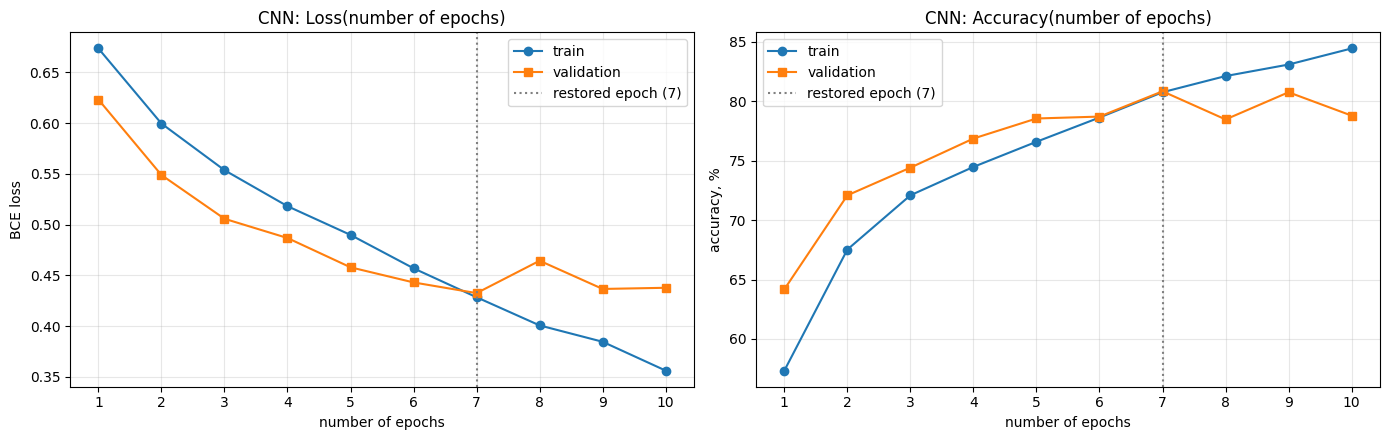

In [7]:
plot_history(hist_cnn, 'CNN')

**Test accuracy 80.4%** (weights from epoch 7, the best on val).

The curves show overfitting. The train loss goes down every epoch, but the validation loss stops falling after epoch 7 (0.433) and then moves around 0.44-0.46. Train accuracy keeps growing (84.5% at epoch 10), while validation accuracy stays at 78-81%. 20 000 photos are not much for 1.35 million parameters, and without augmentation the network starts to memorize the training images. Because of early stopping the weights of epoch 7 are used instead of epoch 10 (val accuracy 80.8% vs 78.8%).

### 1.2. The same CNN with augmentation

Same architecture and optimizer. The only difference is the training images: every epoch the network gets a random crop of 60-100% of each image (resized back to 150 x 150) and a random horizontal flip. This gives "new" images from the same 20 000, so the network has to learn the animal and not specific pixels. The task is harder now, so I train for 25 epochs.

In [8]:
torch.manual_seed(42)
cnn_aug = CNNModel().to(device)
optimizer = optim.Adam(cnn_aug.parameters(), lr=0.001)
hist_cnn_aug = fit(cnn_aug, train_loader_aug, val_loader, criterion, optimizer, num_epochs=25, name='CNN + aug')

test_loss, test_acc = evaluate(cnn_aug, test_loader, criterion)
results['CNN, 3 conv + augmentation'] = {'val acc, %': hist_cnn_aug['val_acc'][hist_cnn_aug['best_epoch'] - 1], 'test acc, %': test_acc,
                                         'test loss': test_loss}
print(f'CNN + augmentation: accuracy on test data {test_acc:.2f}%')

CNN + aug epoch  1/25: train loss 0.6708, train acc 57.77% | val loss 0.6182, val acc 63.41% (22 s)


CNN + aug epoch  2/25: train loss 0.6067, train acc 67.12% | val loss 0.5601, val acc 70.96% (11 s)


CNN + aug epoch  3/25: train loss 0.5668, train acc 70.18% | val loss 0.5298, val acc 72.29% (11 s)


CNN + aug epoch  4/25: train loss 0.5325, train acc 73.28% | val loss 0.5335, val acc 72.53% (11 s)


CNN + aug epoch  5/25: train loss 0.4967, train acc 76.19% | val loss 0.4707, val acc 77.07% (10 s)


CNN + aug epoch  6/25: train loss 0.4754, train acc 77.84% | val loss 0.4392, val acc 78.71% (8 s)


... (16 outputs left out)

CNN + aug epoch 23/25: train loss 0.3008, train acc 87.56% | val loss 0.3090, val acc 86.67% (12 s)


CNN + aug epoch 24/25: train loss 0.2987, train acc 87.47% | val loss 0.3111, val acc 86.87% (11 s)


CNN + aug epoch 25/25: train loss 0.2979, train acc 87.75% | val loss 0.2961, val acc 87.55% (12 s)
CNN + aug: weights of epoch 25 restored (lowest val loss 0.2961), total time 4.8 min


CNN + augmentation: accuracy on test data 87.44%


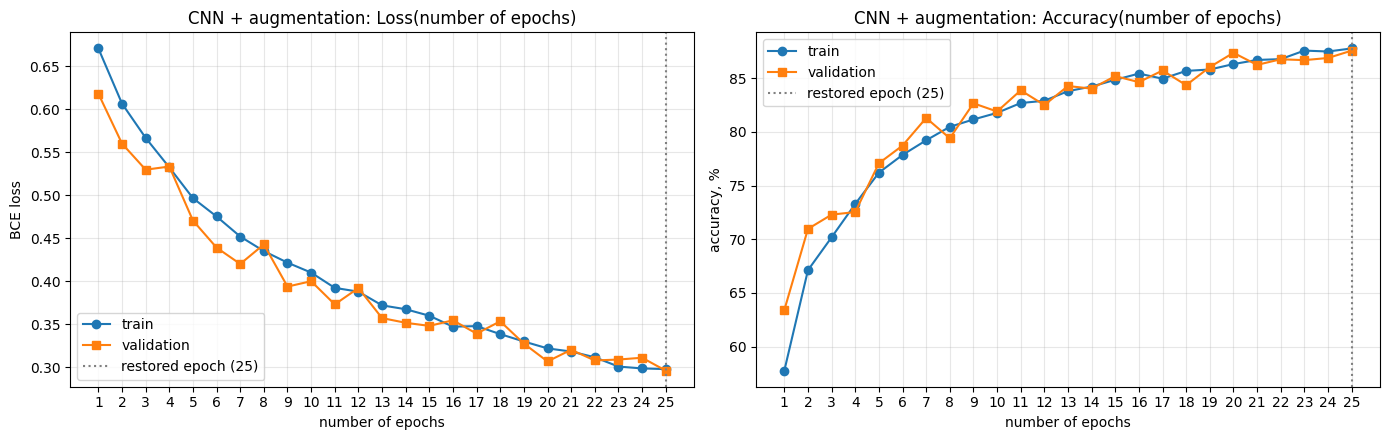

In [9]:
plot_history(hist_cnn_aug, 'CNN + augmentation')

**Test accuracy 87.4%**, 7 points more than without augmentation with the same network.

The train and validation curves now go together for all 25 epochs, and the gap after epoch 7 is gone. Augmented images are harder than the validation ones, so train accuracy stays at the validation level. Both curves are still rising at epoch 25 (the best validation loss is at the last epoch), so more epochs would help a bit. But a small CNN from scratch is still far behind the transfer models.

## Part 2. Transfer learning

Networks trained on ImageNet (1.2 million photos, 1000 classes, including many cat and dog breeds) already extract good features from photos. I freeze their convolutional part and train only a small new classifier on top.

Pretrained models need 224 x 224 images normalized with the ImageNet mean and std, so Part 2 has its own loaders. The only augmentation is a horizontal flip.

In [10]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tl_size = 224
tl_transforms = {
    'train': transforms.Compose([transforms.Resize((tl_size, tl_size)), transforms.RandomHorizontalFlip(),
                                 transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
    'eval': transforms.Compose([transforms.Resize((tl_size, tl_size)),
                                transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]),
}
train_loader_tl = make_loader(train, tl_transforms['train'], shuffle=True)
val_loader_tl = make_loader(val, tl_transforms['eval'], shuffle=False)
test_loader_tl = make_loader(test, tl_transforms['eval'], shuffle=False)

### 2.1. VGG16

The convolutional part of VGG16 with ImageNet weights is frozen. On top: `AdaptiveAvgPool(7x7)`, Dense 256 + ReLU, Dropout(0.5) and one output neuron. Adam with lr = 1e-5, 5 epochs.

In [11]:
vgg16_net = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features
for param in vgg16_net.parameters():
    param.requires_grad = False                                      


class VGG16TransferModel(nn.Module):
    def __init__(self, vgg16_features):
        super(VGG16TransferModel, self).__init__()
        self.features = vgg16_features
        self.avgpool = nn.AdaptiveAvgPool2d((7, 7))
        self.fc1 = nn.Linear(512 * 7 * 7, 256)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, 1)

    def forward(self, x):
        x = self.avgpool(self.features(x))
        x = torch.flatten(x, 1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)


torch.manual_seed(42)
vgg_model = VGG16TransferModel(vgg16_net).to(device)
print(f'VGG16 transfer: trainable {n_trainable(vgg_model):,} of {sum(p.numel() for p in vgg_model.parameters()):,} parameters')

optimizer = optim.Adam(vgg_model.parameters(), lr=1e-5)
hist_vgg = fit(vgg_model, train_loader_tl, val_loader_tl, criterion, optimizer, num_epochs=5, name='VGG16')

test_loss, test_acc = evaluate(vgg_model, test_loader_tl, criterion)
results['VGG16 transfer'] = {'val acc, %': hist_vgg['val_acc'][hist_vgg['best_epoch'] - 1], 'test acc, %': test_acc, 'test loss': test_loss}
print(f'VGG16 transfer: accuracy on test data {test_acc:.2f}%')

VGG16 transfer: trainable 6,423,041 of 21,137,729 parameters


VGG16 epoch  1/5: train loss 0.1024, train acc 97.19% | val loss 0.0397, val acc 98.84% (124 s)


VGG16 epoch  2/5: train loss 0.0362, train acc 98.82% | val loss 0.0338, val acc 98.96% (157 s)


VGG16 epoch  3/5: train loss 0.0288, train acc 98.99% | val loss 0.0316, val acc 99.04% (185 s)


VGG16 epoch  4/5: train loss 0.0229, train acc 99.30% | val loss 0.0310, val acc 99.08% (194 s)


VGG16 epoch  5/5: train loss 0.0191, train acc 99.41% | val loss 0.0303, val acc 99.08% (193 s)
VGG16: weights of epoch 5 restored (lowest val loss 0.0303), total time 14.2 min


VGG16 transfer: accuracy on test data 98.84%


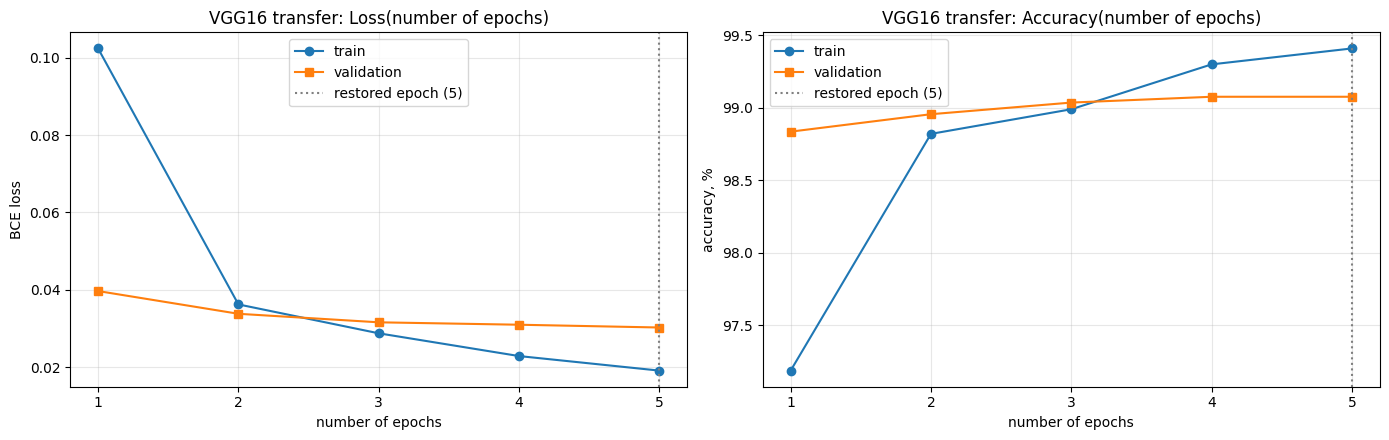

In [12]:
plot_history(hist_vgg, 'VGG16 transfer')

**Test accuracy 98.84%** after 5 epochs, and already 98.8% on val after the first one. Only the head is trained: 6.4 of 21.1 million parameters, almost all of them in the dense layer 25 088 → 256. Train and validation loss are close (0.019 vs 0.030), so with frozen features there is almost no overfitting. One epoch takes about 3 min, mostly the forward pass through VGG16.

### 2.2. One more model: ResNet-50

I use ResNet-50 with the `IMAGENET1K_V2` weights: 80.9% top-1 on ImageNet vs 71.6% for VGG16, and about 4 times fewer computations (4.1 vs 15.5 GFLOPs per image). The backbone is frozen, and the 1000-class layer is replaced with a head 2048 → 256 → 1. Only the head is trained (0.5 million parameters), so a larger lr = 1e-3 is fine. 5 epochs.

In [13]:
resnet_model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
for param in resnet_model.parameters():
    param.requires_grad = False

# new head instead of the 1000-class ImageNet layer: 2048 -> 256 -> 1 (only this part is trained)
torch.manual_seed(42)
resnet_model.fc = nn.Sequential(nn.Linear(resnet_model.fc.in_features, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 1))
resnet_model = resnet_model.to(device)
print(f'ResNet50 transfer: trainable {n_trainable(resnet_model):,} of {sum(p.numel() for p in resnet_model.parameters()):,} parameters')

optimizer = optim.Adam(resnet_model.fc.parameters(), lr=1e-3)
hist_resnet = fit(resnet_model, train_loader_tl, val_loader_tl, criterion, optimizer, num_epochs=5, name='ResNet50')

test_loss, test_acc = evaluate(resnet_model, test_loader_tl, criterion)
results['ResNet50 transfer'] = {'val acc, %': hist_resnet['val_acc'][hist_resnet['best_epoch'] - 1], 'test acc, %': test_acc, 'test loss': test_loss}
print(f'ResNet50 transfer: accuracy on test data {test_acc:.2f}%')

ResNet50 transfer: trainable 524,801 of 24,032,833 parameters


ResNet50 epoch  1/5: train loss 0.0613, train acc 97.79% | val loss 0.0358, val acc 98.71% (184 s)


ResNet50 epoch  2/5: train loss 0.0323, train acc 98.86% | val loss 0.0411, val acc 98.47% (132 s)


ResNet50 epoch  3/5: train loss 0.0283, train acc 98.93% | val loss 0.0299, val acc 98.92% (129 s)


ResNet50 epoch  4/5: train loss 0.0221, train acc 99.17% | val loss 0.0296, val acc 98.92% (129 s)


ResNet50 epoch  5/5: train loss 0.0199, train acc 99.24% | val loss 0.0333, val acc 99.12% (129 s)


ResNet50: weights of epoch 4 restored (lowest val loss 0.0296), total time 11.7 min


ResNet50 transfer: accuracy on test data 98.56%


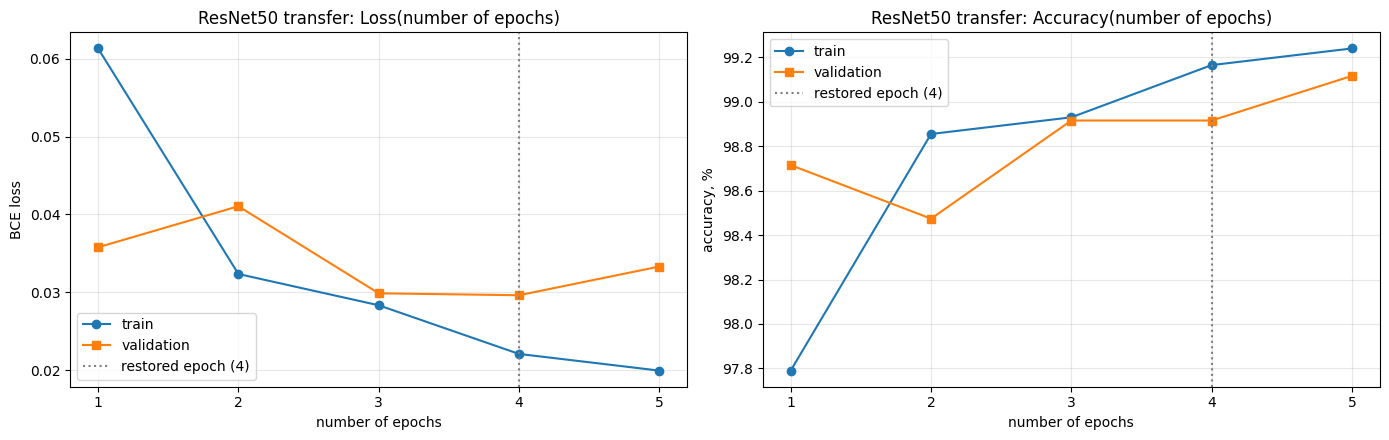

In [14]:
plot_history(hist_resnet, 'ResNet50 transfer')

**Test accuracy 98.56%.** 0.5 million trainable parameters, about 2 min per epoch instead of 3 min for VGG16. The validation loss is lowest at epoch 4 (0.0296), so these weights are kept. The accuracy curves change in steps of 0.04%, which is one validation image out of 2490, so the differences between epochs are just a few images.

### 2.3. Comparison of all models

The best model for inference is chosen by validation accuracy. The table shows the validation accuracy of the weights that are actually used (the restored epoch), not the maximum over epochs.

,"val acc, %","test acc, %",test loss
"CNN, 3 conv",80.843,80.36,0.408
"CNN, 3 conv + augmentation",87.550,87.44,0.296
VGG16 transfer,99.076,98.84,0.033
ResNet50 transfer,98.916,98.56,0.041


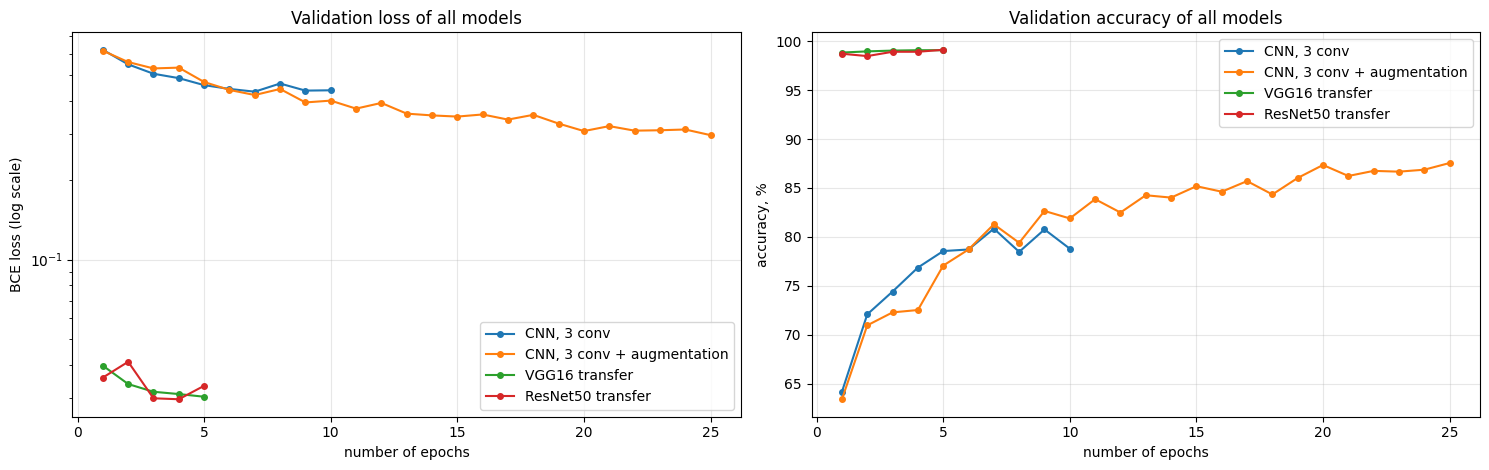

best model by validation accuracy: VGG16 transfer


In [15]:
summary = pd.DataFrame(results).T
display(summary.round(3))

histories = {'CNN, 3 conv': hist_cnn, 'CNN, 3 conv + augmentation': hist_cnn_aug,
             'VGG16 transfer': hist_vgg, 'ResNet50 transfer': hist_resnet}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for name, h in histories.items():
    ep = np.arange(1, len(h['val_loss']) + 1)
    axes[0].plot(ep, h['val_loss'], 'o-', ms=4, label=name)
    axes[1].plot(ep, h['val_acc'], 'o-', ms=4, label=name)
axes[0].set_title('Validation loss of all models'); axes[0].set_ylabel('BCE loss (log scale)'); axes[0].set_yscale('log')
axes[1].set_title('Validation accuracy of all models'); axes[1].set_ylabel('accuracy, %')
for ax in axes:
    ax.set_xlabel('number of epochs'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

best_name = summary['val acc, %'].idxmax()
best_model = {'CNN, 3 conv': cnn, 'CNN, 3 conv + augmentation': cnn_aug,
              'VGG16 transfer': vgg_model, 'ResNet50 transfer': resnet_model}[best_name]
best_transform = tl_transforms['eval'] if 'transfer' in best_name else data_transforms['test']
print('best model by validation accuracy:', best_name)

### 2.4. Inference on custom images

Both transfer models are far ahead of the CNNs. VGG16 is better on validation (99.08% vs 98.92% for ResNet-50, 4 images out of 2490), so I use it for inference. On test it is also better: 98.84% vs 98.56% (7 images out of 2500). The difference is small, both models are good.

`predict_image` loads an image, applies the same preprocessing as for the chosen model and returns the class and its probability. The two photos in `MLT/custom_images/` are not from the dataset, they are from Wikimedia Commons. To check another photo, put it in that folder and add the path to `custom_images`.

MLT/custom_images/cat.jpg: cat (100.00%)


MLT/custom_images/dog.jpg: dog (100.00%)


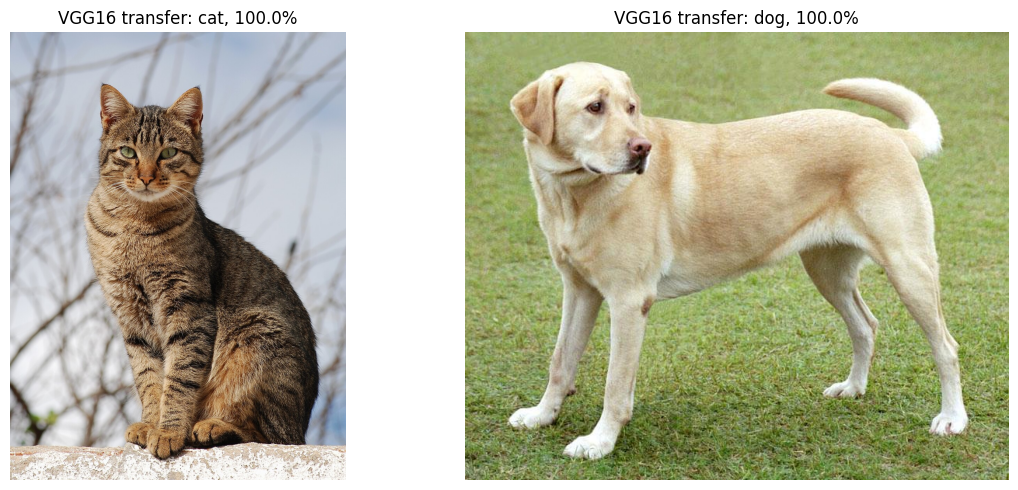

In [16]:
def predict_image(image_path, model=best_model, transform=best_transform):
    """Says whether the image shows a cat or a dog.

    image_path - path to any image file (jpg, png, also grayscale or with alpha channel)
    model      - trained model with one output logit (1 = dog)
    transform  - the same preprocessing that was used for this model on the validation / test data
    returns    - (predicted class, its probability)
    """
    image = Image.open(image_path).convert('RGB')
    x = transform(image).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        p_dog = torch.sigmoid(model(x)).item()
    return ('dog', p_dog) if p_dog > 0.5 else ('cat', 1 - p_dog)


custom_images = ['MLT/custom_images/cat.jpg', 'MLT/custom_images/dog.jpg']
fig, axes = plt.subplots(1, len(custom_images), figsize=(6 * len(custom_images), 5))
for ax, path in zip(np.atleast_1d(axes), custom_images):
    label, prob = predict_image(path)
    print(f'{path}: {label} ({prob * 100:.2f}%)')
    ax.imshow(Image.open(path).convert('RGB')); ax.axis('off')
    ax.set_title(f'{best_name}: {label}, {prob * 100:.1f}%')
plt.tight_layout(); plt.show()

In [17]:
# the same custom images through every model, P(dog)
all_models = {'CNN, 3 conv': (cnn, data_transforms['test']),
              'CNN, 3 conv + augmentation': (cnn_aug, data_transforms['test']),
              'VGG16 transfer': (vgg_model, tl_transforms['eval']),
              'ResNet50 transfer': (resnet_model, tl_transforms['eval'])}
def p_dog(path, model, transform):
    label, prob = predict_image(path, model, transform)
    return prob if label == 'dog' else 1 - prob


table = {name: {os.path.basename(p): p_dog(p, m, tf) for p in custom_images} for name, (m, tf) in all_models.items()}
display(pd.DataFrame(table).T.round(4).add_prefix('P(dog), '))

,"P(dog), cat.jpg","P(dog), dog.jpg"
"CNN, 3 conv",0.2444,0.9957
"CNN, 3 conv + augmentation",0.0020,0.9985
VGG16 transfer,0.0000,1.0000
ResNet50 transfer,0.0000,1.0000


Both photos are classified correctly with a probability close to 100%. The table shows how sure each model is: the plain CNN is not very sure about the cat (P(dog) = 0.24), with augmentation it is 0.002, and both transfer models give 0.0000 for the cat and 1.0000 for the dog.

## Conclusions

1. Part 1. The CNN with 3 convolutional layers gets **80.4%** on test and starts to overfit after about 7 epochs. With simple augmentation (random crops and flips) the same network gets **87.4%** and doesn't overfit in 25 epochs.
2. Part 2. Transfer learning with frozen ImageNet features gives **98.84% (VGG16)** and **98.56% (ResNet-50)** on test after 5 epochs, with only a small head trained. That is 11 points more than the best CNN from scratch. ResNet-50 is almost as good with 12 times fewer trainable parameters and faster epochs.
3. The best model by validation (VGG16) is used in `predict_image`, and it classifies both custom photos correctly.
4. The number of epochs and the best model were chosen on validation, the test set was only used for the final numbers.